Initialise ifcopenshell libraries and conditions

In [442]:
import numpy as np
import ifcopenshell

# for some reason ifcopenshell.api is not imported when importing ifcopenshell, so we need to import it explicitly
import ifcopenshell.api.root
import ifcopenshell.api.unit
import ifcopenshell.api.context
import ifcopenshell.api.project
import ifcopenshell.api.geometry

model = ifcopenshell.file()

# create the root entity (IfcProject) and set it as the root of the model
ifcopenshell.api.root.create_entity(model, ifc_class="IfcProject")

# set coordinates to be in meters
length = ifcopenshell.api.unit.add_si_unit(model, unit_type="LENGTHUNIT")
ifcopenshell.api.unit.assign_unit(model, units=[length])

# create contexts for 3D model, plan view and body
model3d = ifcopenshell.api.context.add_context(model, context_type="Model")
plan = ifcopenshell.api.context.add_context(model, context_type="Plan")
body = ifcopenshell.api.context.add_context(model, 
    context_type="Model", context_identifier="Body", target_view="MODEL_VIEW", parent=model3d)

# add some contexts for axes and annotations
ifcopenshell.api.context.add_context(model,
    context_type="Model", context_identifier="Axis", target_view="GRAPH_VIEW", parent=model3d)
ifcopenshell.api.context.add_context(model,
    context_type="Plan", context_identifier="Axis", target_view="GRAPH_VIEW", parent=plan)
ifcopenshell.api.context.add_context(model,
    context_type="Model", context_identifier="Box", target_view="MODEL_VIEW", parent=model3d)
ifcopenshell.api.context.add_context(model,
    context_type="Plan", context_identifier="Annotation", target_view="PLAN_VIEW", parent=plan)


# create the project structure components for use in IfcRelAggregates
project = model.by_type("IfcProject")[0]
# site = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSite", name="Main Site")
# building = ifcopenshell.api.root.create_entity(model, ifc_class="IfcBuilding", name="Building")
site = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSite", name="Main Site")
building = ifcopenshell.api.root.create_entity(model, ifc_class="IfcBuilding", name="Building")
storey = model.create_entity("IfcBuildingStorey", Name="Ground", Elevation=0.0)

# IfcRelAggregates is used to define the hierarchical structure of the building model.
model.create_entity("IfcRelAggregates", RelatingObject=project, RelatedObjects=[site])
model.create_entity("IfcRelAggregates", RelatingObject=site, RelatedObjects=[building])
model.create_entity("IfcRelAggregates", RelatingObject=building, RelatedObjects=[storey])


#23=IfcRelAggregates($,$,$,$,#19,(#20))

Create function to create IfcSpaces, Walls, Floors

In [443]:
import profile

def create_space(length, width, name, origin, height = 3.0):
    
    # create the specific room ifcspace and relate it to the storey in the model hierarchy
    ifcspace = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSpace", name=name)
    model.create_entity("IfcRelAggregates", RelatingObject=storey, RelatedObjects=[ifcspace])

    # create the actual space entity with geometry and relate it to the ifcspace in the model hierarchy
    room_space = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSpace", name=name)
    # model.create_entity("IfcRelAggregates", RelatingObject=storey, RelatedObjects=[space])

    matrix = np.eye(4)
    matrix[:,3][0:3] = origin
    ifcopenshell.api.geometry.edit_object_placement(model, product=room_space, matrix=matrix, is_si=False)

    profile = model.create_entity("IfcRectangleProfileDef",
        ProfileName=f"{name} footprint", ProfileType="AREA", 
        XDim=length, YDim=width)
    
    space_rep = ifcopenshell.api.geometry.add_profile_representation(
        model, context=body, profile=profile, depth=height)
    
    #### this assigns the geometric representation to the ifcspace, which is what allows it to be visualized in a viewer.
    #### not actually needed so can hide. Maybe useful to keep it for debugging purposes though.
    # ifcopenshell.api.geometry.assign_representation(
    #     model, product=room_space, representation=space_rep)
    
    #### the below is supposed to assign a transparent style to the space. But doesn't work. Comes up as blue in the viewer
    # style = ifcopenshell.api.style.add_style(model)
    # ifcopenshell.api.style.add_surface_style(
    #     model,
    #     style=style,
    #     ifc_class="IfcSurfaceStyleShading",
    #     attributes={
    #         "SurfaceColour": {"Name": None, "Red": 0.7, "Green": 0.9, "Blue": 1.0},
    #         "Transparency": 1,  # 0 = opaque, 1 = fully transparent
    #     }
    # )
    # ifcopenshell.api.style.assign_representation_styles(model,
    #                 shape_representation=room_space.Representation.Representations[0],
    #                 styles=[style]
    #             )
    model.create_entity("IfcRelContainedInSpatialStructure", RelatingStructure=ifcspace, RelatedElements=[room_space])

    return ifcspace, room_space


# define a function to add ifcwall to the model
def create_wall(length, name: str, origin, rotate, ifcspace):
    wall = ifcopenshell.api.root.create_entity(model, ifc_class="IfcWall", name=name)
    
    wall_rep = ifcopenshell.api.geometry.add_wall_representation(model,
        context=body, length=length, height=3.0, thickness=0.2)
    
    matrix = np.eye(4)
    if rotate:
        matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix
    matrix[:,3][0:3] = origin
    
    ifcopenshell.api.geometry.edit_object_placement(model, product=wall, matrix=matrix, is_si=False)
    ifcopenshell.api.geometry.assign_representation(model, product=wall, representation=wall_rep)

    # this part is important because it relates the wall back to the hierarchy of the ifc model defined before
    ifcopenshell.api.spatial.assign_container(model, relating_structure=ifcspace, products=[wall])

    return wall

def create_slab(length, width, name, origin, ifcspace):
    slab = ifcopenshell.api.root.create_entity(model, ifc_class="IfcSlab", name=name)

    # Create a rectangular profile for the slab with your desired dimensions
    profile = model.create_entity("IfcRectangleProfileDef", ProfileName="slab", ProfileType="AREA",
        XDim=length, YDim=width)

    slab_rep = ifcopenshell.api.geometry.add_profile_representation(model, context=body, profile=profile, depth=0.2)

    matrix = np.eye(4)
    matrix[:,3][0:3] = origin
    ifcopenshell.api.geometry.edit_object_placement(model, product=slab, matrix=matrix, is_si=True)
    ifcopenshell.api.geometry.assign_representation(model, product=slab, representation=slab_rep)
    ifcopenshell.api.spatial.assign_container(model, relating_structure=ifcspace, products=[slab])
    
    return slab


# define a function to add a room to the model, which is just an ifcspace with physical geometry assigned
def create_room(length, width, name, origin):
    
    room_dict = {}

    [ifcspace, space] = create_space(length=length, width=width, name=name, origin=origin+np.array([length/2, width/2, 0]))

    room_dict[name+"wallN"] = create_wall(length=length, name=name+"wallN", origin=origin+np.array([0, width, 0]), rotate=False, ifcspace=ifcspace)
    room_dict[name+"wallS"] = create_wall(length=length, name=name+"wallS", origin=origin+np.array([0,-0.2,0]), rotate=False, ifcspace=ifcspace)

    room_dict[name+"wallE"] = create_wall(length=width+0.4, name=name+"wallE", origin=origin+np.array([length+0.2, -0.2, 0]), rotate=True, ifcspace=ifcspace)
    room_dict[name+"wallW"] = create_wall(length=width+0.4, name=name+"wallW", origin=origin+np.array([0, -0.2, 0]), rotate=True, ifcspace=ifcspace)

    room_dict[name+"slab"] = create_slab(length=length+0.4, width=width+0.4, name=name+"slab", origin=origin+np.array([length/2, width/2, -0.2]), ifcspace=ifcspace)   
    
    return [space, room_dict]

In [444]:
# Define a function to add space boundaries to the model. 
# This function creates an IfcRelSpaceBoundary entity, relates it to the space and the building element, 
# and sets the physical and internal/external attributes.

def create_rel(space, element, physical="VIRTUAL", internal_external="INTERNAL", name=None):
    rel = ifcopenshell.api.root.create_entity(
        model,
        ifc_class="IfcRelSpaceBoundary2ndLevel",
        name=name
    )
    ifcopenshell.api.boundary.edit_attributes(
        model,
        entity=rel,
        relating_space=space,
        related_building_element=element,
    )
    rel.PhysicalOrVirtualBoundary = physical
    rel.InternalOrExternalBoundary = internal_external
    return rel

Function for create openings

In [445]:
# adds openings, specifically for doors
# for now, this requires knowledge of both the walls of both spaces, including names. Can be tedious

# this currently creates two openings if there are two walls, but they are both related to the same opening element for simplicity. 
# This is because the opening element is what relates the two spaces together, and the geometry is just for visualisation purposes.
# this does not mean that the extra opening is a "leftover" element within the IFC model. It exists purely as a physical geometrical visualisation. It is not ever represented as relationship to an IfcSpace.
# openings are essentially viewed as subtractions to the wall.
# as a matter of fact, you cannot simply (or at least conventionally) define a relationship between an opening and any other object directly. However they can be defined as the link between two IfcSpace entities.
def create_opening(width, height, name, origin, ifcspace1, wall1, ifcspace2=None, wall2=None):
    opening = ifcopenshell.api.root.create_entity(model, ifc_class="IfcOpeningElement", name=name)
    opening_rep = ifcopenshell.api.geometry.add_wall_representation(model,
        context=body, length=width, height=height, thickness=0.4)
    ifcopenshell.api.geometry.assign_representation(model, product=opening, representation=opening_rep)

    matrix = np.eye(4)
    if wall1.Name[-1] == "W" or wall1.Name[-1] == "E":
        matrix = ifcopenshell.util.placement.rotation(90, "Z") @ matrix
    matrix[:,3][0:3] = origin

    ifcopenshell.api.geometry.edit_object_placement(model, product=opening, matrix=matrix, is_si=True)

    # issue. I suspect that this will need to select both walls that the opening intersects with
    # i think it's fine, because technically i just need to know which space the opening connects to.
    # plus i am manually placing the openings. it's more for geometry and visuals
    ifcopenshell.api.feature.add_feature(model, feature=opening, element=wall1)
    ifcopenshell.api.spatial.assign_container(model, relating_structure=ifcspace1, products=[opening])


    if (wall2 is not None):
        opening2 = ifcopenshell.api.root.create_entity(model, ifc_class="IfcOpeningElement", name=name)
        opening2_rep = ifcopenshell.api.geometry.add_wall_representation(model,
            context=body, length=width, height=height, thickness=0.4)
        ifcopenshell.api.geometry.assign_representation(model, product=opening2, representation=opening2_rep)

        ifcopenshell.api.geometry.edit_object_placement(model, product=opening2, matrix=matrix, is_si=True)

        ifcopenshell.api.feature.add_feature(model, feature=opening2, element=wall2)
        ifcopenshell.api.spatial.assign_container(model, relating_structure=ifcspace2, products=[opening2])
        # b2=create_rel(ifcspace2, opening2, name=name+"_Boundary")
        
        # create two way relationship entities between two rooms
        b1=create_rel(ifcspace1, opening, name=name+"_Boundary")
        b2=create_rel(ifcspace2, opening, name=name+"_Boundary")

        # the below is the same as create_space_boundary but with an added element
        ifcopenshell.api.boundary.edit_attributes(
            model,
            entity=b1,
            relating_space=ifcspace1,
            related_building_element=opening,
            corresponding_boundary=b2
        )

        ifcopenshell.api.boundary.edit_attributes(
            model,
            entity=b2,
            relating_space=ifcspace2,
            related_building_element=opening, # this is intentional, so b2 can be related to b1 through the same opening. openign2 is just for geometry visualisation
            corresponding_boundary=b1
        )
    return opening

Functions for extracting information from model

In [446]:
# defined as a dictionary, because there can be multiple boundaries related by openings
def get_boundary_room(space):
    b_room = {}
    for boundary in space.BoundedBy:
        corr_boundary = boundary.CorrespondingBoundary
        b_room[boundary.RelatedBuildingElement.Name] = corr_boundary.RelatingSpace
    return b_room

def get_openings(space):
    openings = {}
    for boundary in space.BoundedBy:
        if boundary.RelatedBuildingElement.is_a("IfcOpeningElement"):
            openings[boundary.RelatedBuildingElement.Name] = boundary.RelatedBuildingElement
    return openings

def get_coordinates(entity):
    matrix = ifcopenshell.util.placement.get_local_placement(entity.ObjectPlacement)
    return matrix[:,3][0:3]

###### other functions to add later:
# get length/width of a space
# calculate distance between spaces

Model Generation Code

In [ ]:
# a = create_room(length=5, width=4, name="Room1", origin=(0,0,0))
# # when adding rooms next to each other, make sure to account for wall thickness so that they are flush with each other.
# # there is also way to way to account for shared walls between rooms, but for simplicity we will just add separate walls
# # for each room and make sure they are flush with each other
# b = create_room(length=3, width=4, name="Room2", origin=(5.2,0,0))
# c = create_room(length=8.2, width=2, name="Corridor", origin=(0,4.2,0))

# # Define rooms in order. Preferably from inside out
# # d=create_opening(width=1, height=2, name="Room1_Door", origin=(2, 4, 0), ifcspace1=a[0], wall1=a[1]["Room1wallN"], ifcspace2=c[0], wall2=c[1]["CorridorwallS"])
# d=create_opening(width=1, height=2, name="Room1_Door", origin=(2, 4, 0), ifcspace1=a[0], wall1=a[1]["Room1wallN"], ifcspace2=c[0], wall2=c[1]["CorridorwallS"])


entry_lobby = create_room(length=6, width=8, name="entry_lobby", origin=(0,6,0))
s1_office = create_room(length=6, width=6, name="s1_office", origin=(6.2,3,0))
s2_office = create_room(length=6, width=6, name="s2_office", origin=(12.4,3,0))
s3_office = create_room(length=6, width=6, name="s3_office", origin=(18.6,3,0))
east_lobby = create_room(length=4, width=9, name="east_lobby", origin=(24.8,3,0))
west_corridor = create_room(length=10, width=2.8, name="west_corridor", origin=(6.2,9.2,0))
east_corridor = create_room(length=8.2, width=2.8, name="east_corridor", origin=(16.4,9.2,0))
n1_office = create_room(length=3, width=6, name="n1_office", origin=(6.2,12.2,0))
n2_office = create_room(length=4, width=6, name="n2_office", origin=(9.4,12.2,0))
north_corridor = create_room(length=2, width=6, name="north_corridor", origin=(13.6,12.2,0))
north_store = create_room(length=2, width=6, name="north_store", origin=(15.8,12.2,0))
n3_office = create_room(length=4, width=6, name="n3_office", origin=(18,12.2,0))
ne_lobby = create_room(length=6.6, width=6, name="ne_lobby", origin=(22.2,12.2,0))
north_clean = create_room(length=4.2, width=3, name="north_clean", origin=(13.6,18.4,0))


west_exit = create_opening(width=1, height=2, name="west_exit", origin=(0, 8, 0), ifcspace1=entry_lobby[0], wall1=entry_lobby[1]["entry_lobbywallW"])
door_entry_lobby_west_corridor = create_opening(width=1, height=2, name="door_entry_lobby_west_corridor", origin=(6.2, 10, 0), ifcspace1=entry_lobby[0], wall1=entry_lobby[1]["entry_lobbywallE"], ifcspace2=west_corridor[0], wall2=west_corridor[1]["west_corridorwallW"])
door_s1_office_west_corridor = create_opening(width=1, height=2, name="door_s1_office_west_corridor", origin=(9, 9, 0), ifcspace1=s1_office[0], wall1=s1_office[1]["s1_officewallN"], ifcspace2=west_corridor[0], wall2=west_corridor[1]["west_corridorwallS"])
door_s2_office_west_corridor = create_opening(width=1, height=2, name="door_s2_office_west_corridor", origin=(13.2, 9, 0), ifcspace1=s2_office[0], wall1=s2_office[1]["s2_officewallN"], ifcspace2=west_corridor[0], wall2=west_corridor[1]["west_corridorwallS"])
door_n1_office_west_corridor = create_opening(width=1, height=2, name="door_n1_office_west_corridor", origin=(7.5, 12, 0), ifcspace1=n1_office[0], wall1=n1_office[1]["n1_officewallS"], ifcspace2=west_corridor[0], wall2=west_corridor[1]["west_corridorwallN"])
door_n1_office_n2_office = create_opening(width=1, height=2, name="door_n1_office_n2_office", origin=(9.4, 16, 0), ifcspace1=n1_office[0], wall1=n1_office[1]["n1_officewallE"], ifcspace2=n2_office[0], wall2=n2_office[1]["n2_officewallW"])
door_west_corridor_east_corridor = create_opening(width=1, height=2, name="door_west_corridor_east_corridor", origin=(16.4, 10, 0), ifcspace1=west_corridor[0], wall1=west_corridor[1]["west_corridorwallE"], ifcspace2=east_corridor[0], wall2=east_corridor[1]["east_corridorwallW"])
door_s3_office_east_corridor = create_opening(width=1, height=2, name="door_s3_office_east_corridor", origin=(20, 9, 0), ifcspace1=s3_office[0], wall1=s3_office[1]["s3_officewallN"], ifcspace2=east_corridor[0], wall2=east_corridor[1]["east_corridorwallS"])
door_n3_office_east_corridor = create_opening(width=1, height=2, name="door_n3_office_east_corridor", origin=(20.5, 12, 0), ifcspace1=n3_office[0], wall1=n3_office[1]["n3_officewallS"], ifcspace2=east_corridor[0], wall2=east_corridor[1]["east_corridorwallN"])
door_ne_lobby_east_corridor = create_opening(width=1, height=2, name="door_ne_lobby_east_corridor", origin=(22.8, 12, 0), ifcspace1=ne_lobby[0], wall1=ne_lobby[1]["ne_lobbywallS"], ifcspace2=east_corridor[0], wall2=east_corridor[1]["east_corridorwallN"])
door_east_corridor_east_lobby = create_opening(width=1, height=2, name="door_east_corridor_east_lobby", origin=(24.8, 10, 0), ifcspace1=east_corridor[0], wall1=east_corridor[1]["east_corridorwallE"], ifcspace2=east_lobby[0], wall2=east_lobby[1]["east_lobbywallW"])
door_north_corridor_west_corridor = create_opening(width=1, height=2, name="door_north_corridor_west_corridor", origin=(14, 12, 0), ifcspace1=north_corridor[0], wall1=north_corridor[1]["north_corridorwallS"], ifcspace2=west_corridor[0], wall2=west_corridor[1]["west_corridorwallN"])
door_north_corridor_north_clean = create_opening(width=1, height=2, name="door_north_corridor_north_clean", origin=(14, 18.2, 0), ifcspace1=north_corridor[0], wall1=north_corridor[1]["north_corridorwallN"], ifcspace2=north_clean[0], wall2=north_clean[1]["north_cleanwallS"])
door_north_clean_north_store = create_opening(width=1, height=2, name="door_north_clean_north_store", origin=(16, 18.2, 0), ifcspace1=north_clean[0], wall1=north_clean[1]["north_cleanwallS"], ifcspace2=north_store[0], wall2=north_store[1]["north_storewallN"])
north_exit = create_opening(width=1, height=2, name="north_exit", origin=(25, 18.2, 0), ifcspace1=ne_lobby[0], wall1=ne_lobby[1]["ne_lobbywallN"])
south_exit = create_opening(width=1, height=2, name="south_exit", origin=(15, 2.8, 0), ifcspace1=s2_office[0], wall1=s2_office[1]["s2_officewallS"])

# b=get_boundary_room(c[0])
# print(b)
# # print("Room1 neighbors:", get_neighbors(a[0]))

# print(get_openings(a[0]))
# opens = get_openings(a[0])

# door1 = opens["Room1_Door"]
# print(get_coordinates(door1))

### TODO add openings in wall, then add space boundaries for openings connecting rooms

model.write("Function_Model_v2.ifc")

C:\Users\Richard\AppData\Local\Temp\ipykernel_7644\936422816.py:48: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


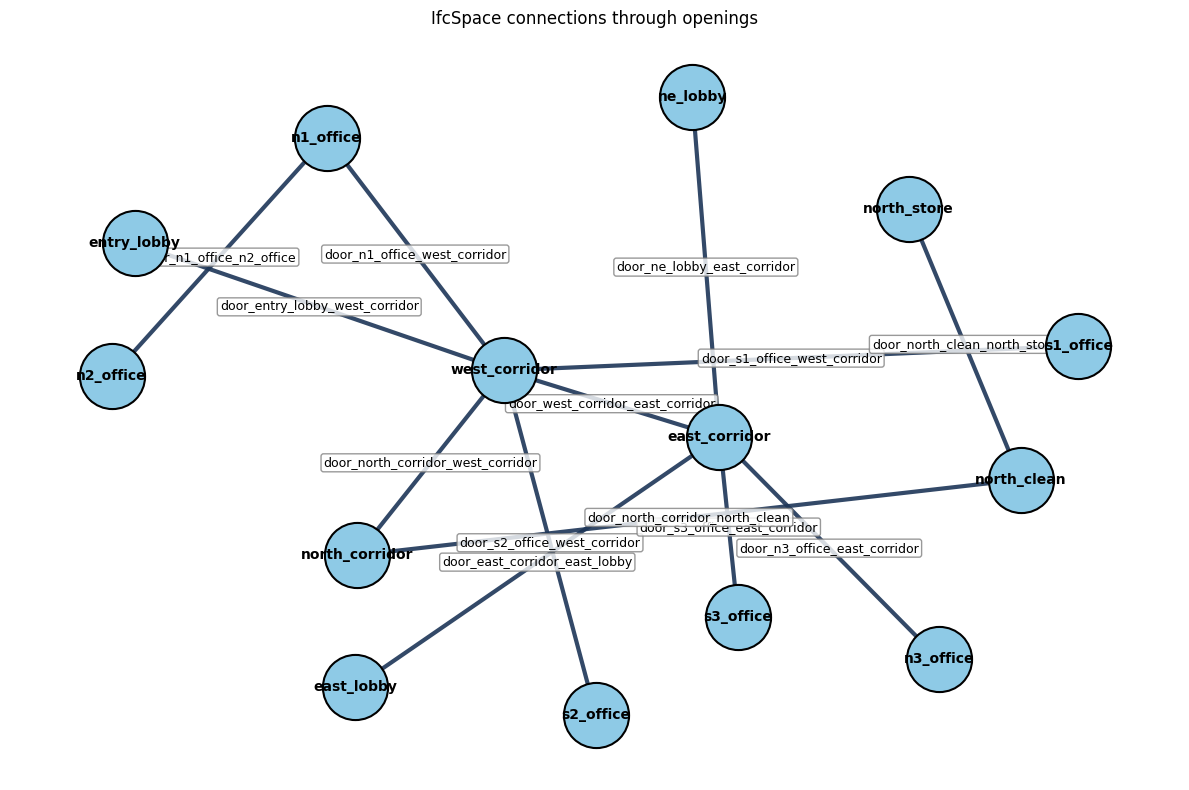

In [448]:
import networkx as nx
import matplotlib.pyplot as plt

def build_nx_space_graph(model):
    G = nx.Graph()

    for space in model.by_type("IfcSpace"):
        s1 = space.Name or f"IfcSpace_{space.id()}"
        G.add_node(s1)

        for b in getattr(space, "BoundedBy", []):
            if not b.is_a("IfcRelSpaceBoundary2ndLevel"):
                continue

            cb = getattr(b, "CorrespondingBoundary", None)
            if not cb:
                continue

            elem = getattr(b, "RelatedBuildingElement", None)
            if not elem or not elem.is_a("IfcOpeningElement"):
                continue

            s2_obj = cb.RelatingSpace
            s2 = s2_obj.Name or f"IfcSpace_{s2_obj.id()}"
            opening_name = elem.Name or f"IfcOpeningElement_{elem.id()}"

            # undirected graph avoids duplicate room-room edges
            if not G.has_edge(s1, s2):
                G.add_edge(s1, s2, opening=opening_name)

    return G


def draw_space_graph_clear(G):
    plt.figure(figsize=(12, 8))
    pos = nx.spring_layout(G, seed=7, k=1.8)

    # nodes
    nx.draw_networkx_nodes(
        G, pos,
        node_size=2200,
        node_color="#8ecae6",
        edgecolors="black",
        linewidths=1.5
    )

    # edges
    nx.draw_networkx_edges(
        G, pos,
        width=3.0,
        edge_color="#1d3557",
        alpha=0.9,
        connectionstyle="arc3,rad=0.08"
    )

    # node labels
    nx.draw_networkx_labels(
        G, pos,
        font_size=10,
        font_weight="bold"
    )

    # edge labels
    edge_labels = {(u, v): d["opening"] for u, v, d in G.edges(data=True)}
    nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=9,
        rotate=False,
        label_pos=0.5,
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="gray",
            alpha=0.8
        )
    )

    plt.title("IfcSpace connections through openings")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# usage
G = build_nx_space_graph(model)
draw_space_graph_clear(G)

In [449]:
import networkx as nx
import plotly.graph_objects as go

def build_nx_space_graph(model):
    """Build a graph of IfcSpaces connected through IfcOpeningElements."""
    G = nx.Graph()

    for space in model.by_type("IfcSpace"):
        s1 = space.Name or f"IfcSpace_{space.id()}"
        G.add_node(s1, ifc_id=space.id())

        for b in getattr(space, "BoundedBy", []):
            if not b.is_a("IfcRelSpaceBoundary2ndLevel"):
                continue

            cb = getattr(b, "CorrespondingBoundary", None)
            if not cb:
                continue

            elem = getattr(b, "RelatedBuildingElement", None)
            if not elem or not elem.is_a("IfcOpeningElement"):
                continue

            s2_obj = cb.RelatingSpace
            s2 = s2_obj.Name or f"IfcSpace_{s2_obj.id()}"
            opening_name = elem.Name or f"IfcOpeningElement_{elem.id()}"

            if not G.has_edge(s1, s2):
                G.add_edge(
                    s1,
                    s2,
                    opening=opening_name,
                    opening_id=elem.id(),
                    boundary_id=b.id(),
                    corresponding_boundary_id=cb.id(),
                )

    return G


def export_interactive_space_graph_html(model, output_html="space_graph.html"):
    G = build_nx_space_graph(model)

    if G.number_of_nodes() == 0:
        print("No IfcSpace connections found.")
        return None

    pos = nx.spring_layout(G, seed=7, k=1.8)

    # edges
    edge_x = []
    edge_y = []
    edge_hover_x = []
    edge_hover_y = []
    edge_hover_text = []

    for u, v, d in G.edges(data=True):
        x0, y0 = pos[u]
        x1, y1 = pos[v]

        edge_x += [x0, x1, None]
        edge_y += [y0, y1, None]

        mx = (x0 + x1) / 2
        my = (y0 + y1) / 2
        edge_hover_x.append(mx)
        edge_hover_y.append(my)
        edge_hover_text.append(
            f"Opening: {d['opening']}<br>"
            f"Opening ID: {d['opening_id']}<br>"
            f"Boundary ID: {d['boundary_id']}<br>"
            f"Corresponding Boundary ID: {d['corresponding_boundary_id']}"
        )

    edge_trace = go.Scatter(
        x=edge_x,
        y=edge_y,
        mode="lines",
        line=dict(width=3, color="#1d3557"),
        hoverinfo="skip",
        name="Connections"
    )

    # invisible hover points for edges
    edge_hover_trace = go.Scatter(
        x=edge_hover_x,
        y=edge_hover_y,
        mode="markers",
        marker=dict(size=14, color="rgba(0,0,0,0)"),
        hoverinfo="text",
        text=edge_hover_text,
        name="Opening info"
    )

    # nodes
    node_x = []
    node_y = []
    node_text = []
    node_hover = []
    node_size = []

    for n, data in G.nodes(data=True):
        x, y = pos[n]
        degree = G.degree(n)

        node_x.append(x)
        node_y.append(y)
        node_text.append(n)
        node_size.append(24 + degree * 4)

        neighbors = list(G.neighbors(n))
        node_hover.append(
            f"Space: {n}<br>"
            f"Ifc ID: {data['ifc_id']}<br>"
            f"Connections: {degree}<br>"
            f"Adjacent to: {', '.join(neighbors) if neighbors else 'None'}"
        )

    node_trace = go.Scatter(
        x=node_x,
        y=node_y,
        mode="markers+text",
        text=node_text,
        textposition="top center",
        hoverinfo="text",
        hovertext=node_hover,
        marker=dict(
            size=node_size,
            color="#8ecae6",
            line=dict(width=2, color="black")
        ),
        name="Spaces"
    )

    fig = go.Figure(data=[edge_trace, edge_hover_trace, node_trace])

    fig.update_layout(
        title="IfcSpace connections through openings",
        hovermode="closest",
        showlegend=False,
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    )

    fig.write_html(output_html, include_plotlyjs=True)
    print(f"Interactive graph exported to: {output_html}")
    print(f"Rooms: {G.number_of_nodes()}, Connections: {G.number_of_edges()}")

    return G, fig


# usage
G, fig = export_interactive_space_graph_html(model, "space_graph.html")

Interactive graph exported to: space_graph.html
Rooms: 14, Connections: 13
